# Employee Sentiment Analysis

**Goal:** label an unlabeled set of employee e-mails with sentiment, explore the data, score and
rank employees month by month, flag flight risks and model monthly sentiment with linear regression.

| Section | Task |
|---|---|
| 0 | Setup & data loading |
| 1 | Sentiment labeling (RoBERTa transformer + VADER cross-check) |
| 2 | Exploratory data analysis |
| 3 | Monthly employee score |
| 4 | Employee ranking |
| 5 | Flight-risk identification (rolling 30 days) |
| 6 | Predictive modeling (linear regression) |
| 7 | Summary |

Supporting code lives in `src/` (`sentiment.py`, `analysis.py`); this notebook calls it and shows every step.
Figures go to `visualization/`, tables to `outputs/`.

## 0. Setup & data loading

In [1]:
# Standard libraries and plotting
import sys, warnings
from pathlib import Path
import numpy as np, pandas as pd
import matplotlib.pyplot as plt, seaborn as sns

# Make the helper modules in src/ importable
ROOT = Path.cwd()
sys.path.insert(0, str(ROOT / "src"))
from sentiment import (build_model_input, transformer_sentiment, vader_sentiment,
                       textblob_sentiment, MODEL_NAME)
from analysis import (monthly_scores, monthly_rankings, flight_risk, flight_risk_bruteforce,
                      monthly_features, ols_summary, SCORE_MAP)

# Output folders for figures and tables
VIS, OUT = ROOT / "visualization", ROOT / "outputs"
VIS.mkdir(exist_ok=True); OUT.mkdir(exist_ok=True)

# Display settings, one colour per sentiment class, and a fixed random seed
warnings.filterwarnings("ignore")
sns.set_theme(style="whitegrid", context="notebook")
PALETTE = {"Positive": "#2a9d8f", "Neutral": "#adb5bd", "Negative": "#e76f51"}
SEED = 42
pd.set_option("display.width", 140)

def save(fig, name):
    """Save a figure into visualization/ and show it inline."""
    fig.tight_layout()
    fig.savefig(VIS / name, dpi=150, bbox_inches="tight")
    plt.show()

In [2]:
# Load the raw, unlabeled dataset and take a first look
raw = pd.read_csv(ROOT / "data" / "test.csv")
print("shape:", raw.shape)
raw.head()

shape: (2191, 4)


,Subject,body,date,from
0,EnronOptions Update!,EnronOptions Announcement\n\n\nWe have updated...,5/10/2010,sally.beck@enron.com
1,(No Subject),"Marc,\n\nUnfortunately, today is not going to ...",7/29/2010,eric.bass@enron.com
2,Phone Screen Interview - Shannon L. Burnham,"When: Wednesday, June 06, 2001 10:00 AM-11:00 ...",7/25/2011,sally.beck@enron.com
3,RE: My new work email,we were thinking papasitos (we can meet somewh...,3/25/2010,johnny.palmer@enron.com
4,Bet,Since you never gave me the $20 for the last t...,5/21/2011,lydia.delgado@enron.com


## 1. Sentiment labeling

**Approach**

1. **Cleaning** – the bodies are raw Enron e-mails with quoted-printable artefacts (`=20`, `=01`, soft line
   breaks `=\n`), URLs and addresses. These are stripped and whitespace collapsed. The subject is prepended
   to the body because it often carries tone ("Congratulations!", "RE: problem with ...").
2. **Primary labeler – transformer (LLM-style encoder)**: `cardiffnlp/twitter-roberta-base-sentiment-latest`,
   a RoBERTa model (PyTorch) fine-tuned for 3-class sentiment. Each message gets P(neg), P(neu), P(pos) and
   the label is the **arg-max** – no hand-tuned thresholds, fully deterministic (`model.eval()`, no sampling).
   Input is truncated at 512 tokens (bodies are ≤ 999 characters, so in practice nothing is cut).
3. **Validation – VADER and TextBlob**, two lexicon-based methods, label the same text independently.
   VADER uses its standard compound-score cut-offs (±0.05). TextBlob gives a polarity in [−1, 1], and the same
   ±0.05 band is used for Neutral so the two lexicon methods are comparable. Agreement and Cohen's κ between
   all three methods act as a sanity check, and disagreements are inspected manually. Neither lexicon method
   changes the final label.

**Why this choice:** a transformer reads context ("not a problem", "unfortunately … will not work") that
word-count lexicons miss, while being small enough to run on CPU in ~1–2 minutes, so results are
reproducible without an API key. Labels are cached to `outputs/labeled_messages.csv`; delete that file to
recompute from scratch.

In [3]:
# Rename the sender column, parse dates (month/day/year) and build the cleaned model input
df = raw.rename(columns={"from": "employee"}).copy()
df["date"] = pd.to_datetime(df["date"], format="%m/%d/%Y")
df["clean_text"] = [build_model_input(s, b) for s, b in zip(df["Subject"], df["body"])]

# The transformer is the slow step, so its output is cached; delete the CSV to recompute
cache = OUT / "labeled_messages.csv"
lab = pd.read_csv(cache) if cache.exists() else None
if lab is not None:
    # Guard against a cache built from different data
    assert len(lab) == len(df) and (lab["clean_text"].fillna("") == df["clean_text"]).all(), "stale cache"
    for c in ["p_negative", "p_neutral", "p_positive", "sentiment", "confidence", "vader_sentiment"]:
        df[c] = lab[c].values
    print("loaded cached transformer + VADER labels")
else:
    # Primary label: RoBERTa transformer (arg-max of the 3 class probabilities)
    df = pd.concat([df, transformer_sentiment(df["clean_text"].tolist())], axis=1)
    # Cross-check 1: VADER
    df["vader_sentiment"] = vader_sentiment(df["clean_text"].tolist()).values
    print("labels computed with", MODEL_NAME)

# Cross-check 2: TextBlob (fast, so it is always recomputed)
df = pd.concat([df.drop(columns=["textblob_polarity", "textblob_sentiment"], errors="ignore"),
                textblob_sentiment(df["clean_text"].tolist())], axis=1)
df.to_csv(cache, index=False)

df[["Subject", "clean_text", "sentiment", "confidence", "vader_sentiment", "textblob_sentiment"]].head(8)

loaded cached transformer + VADER labels


,Subject,clean_text,sentiment,confidence,vader_sentiment,textblob_sentiment
0,EnronOptions Update!,EnronOptions Update!. EnronOptions Announcemen...,Neutral,0.653191,Positive,Positive
1,(No Subject),"Marc, Unfortunately, today is not going to wor...",Negative,0.687916,Positive,Negative
2,Phone Screen Interview - Shannon L. Burnham,Phone Screen Interview - Shannon L. Burnham. W...,Neutral,0.950031,Neutral,Neutral
3,RE: My new work email,RE: My new work email. we were thinking papasi...,Neutral,0.875480,Neutral,Neutral
4,Bet,Bet. Since you never gave me the $20 for the l...,Neutral,0.839355,Positive,Neutral
5,RE: Favor,"RE: Favor. sure, just call me the bank that de...",Neutral,0.889602,Positive,Positive
6,MG Inventory Summaries,MG Inventory Summaries. Inventory summaries fo...,Neutral,0.956579,Neutral,Neutral
7,Forgot the Attachment,Forgot the Attachment. Please print attachment...,Neutral,0.824211,Positive,Positive


In [4]:
# Compare the three methods: label counts, pairwise agreement and Cohen's kappa
from itertools import combinations
from sklearn.metrics import cohen_kappa_score

METHODS = {"Transformer (final)": "sentiment", "VADER": "vader_sentiment", "TextBlob": "textblob_sentiment"}
counts = pd.DataFrame({m: df[c].value_counts() for m, c in METHODS.items()}).loc[["Positive", "Neutral", "Negative"]]
print("Label counts per method:"); print(counts, "\n")

pairs = pd.DataFrame([{"pair": f"{a} vs {b}",
                       "agreement": (df[METHODS[a]] == df[METHODS[b]]).mean(),
                       "cohen_kappa": cohen_kappa_score(df[METHODS[a]], df[METHODS[b]])}
                      for a, b in combinations(METHODS, 2)]).set_index("pair").round(3)
pairs.to_csv(OUT / "labeler_agreement.csv")

# Share of messages where all three methods give the same label
all_agree = ((df.sentiment == df.vader_sentiment) & (df.sentiment == df.textblob_sentiment)).mean()
print(f"All three agree: {all_agree:.1%}   Mean transformer confidence: {df['confidence'].mean():.3f}")
pairs

Label counts per method:
          Transformer (final)  VADER  TextBlob
Positive                  487   1574      1165
Neutral                  1566    444       758
Negative                  138    173       268 

All three agree: 33.9%   Mean transformer confidence: 0.807


,agreement,cohen_kappa
pair,,
Transformer (final) vs VADER,0.429,0.173
Transformer (final) vs TextBlob,0.522,0.238
VADER vs TextBlob,0.653,0.355


In [5]:
# Cross-tables of the final label against each lexicon method
for name, col in [("VADER", "vader_sentiment"), ("TextBlob", "textblob_sentiment")]:
    display(pd.crosstab(df["sentiment"], df[col], margins=True, rownames=["Transformer"], colnames=[name]))

VADER,Negative,Neutral,Positive,All
Transformer,,,,
Negative,66,17,55,138
Neutral,93,414,1059,1566
Positive,14,13,460,487
All,173,444,1574,2191


TextBlob,Negative,Neutral,Positive,All
Transformer,,,,
Negative,62,39,37,138
Neutral,192,664,710,1566
Positive,14,55,418,487
All,268,758,1165,2191


In [6]:
# Highest-confidence examples of each class, to check that the labels make sense
for lab_ in ["Positive", "Negative", "Neutral"]:
    print(f"==== {lab_} (highest confidence) ====")
    for t in df[df.sentiment == lab_].nlargest(3, "confidence")["clean_text"]:
        print(" -", t[:160])

==== Positive (highest confidence) ====
 - Congratulations!. Congratulations on your promotion to Vice President! Well deserved and a nice way to cap off your stay in London. I look forward to celebratin
 - Promotion. Sally, I am so excited for you and your promotion. I have had the privilege to see the impact you have made on this organization, and I am very glad 
 - Promotion. Sally, I am so excited for you and your promotion. I have had the privilege to see the impact you have made on this organization, and I am very glad 
==== Negative (highest confidence) ====
 - comed sucks! 713-853-6203
 - comed sucks! 713-853-6203
 - comed sucks! 713-853-6203
==== Neutral (highest confidence) ====
 - RE: Saturday December 29. which al's formal wear?
 - MW Off-site @ El Lago Lake Conroe, Fletch, Dorland,. Fletch & wife Dorland & wife Lorenz & friend King & wife
 - MW Off-site @ El Lago Lake Conroe, Fletch, Dorland,. Fletch & wife Dorland & wife Lorenz & friend King & wife


In [7]:
# Opposite-polarity disagreements (Positive vs Negative) between the transformer and each lexicon method
for name, col in [("VADER", "vader_sentiment"), ("TextBlob", "textblob_sentiment")]:
    opp = df[((df.sentiment == "Positive") & (df[col] == "Negative")) |
             ((df.sentiment == "Negative") & (df[col] == "Positive"))]
    print(f"\n{len(opp)} opposite-polarity disagreements with {name}")
    # Show a few so they can be judged by eye
    for _, r in opp.head(4).iterrows():
        print(f"  [RoBERTa={r.sentiment:8s} {name}={r[col]:8s}]", r.clean_text[:140])


69 opposite-polarity disagreements with VADER
  [RoBERTa=Negative VADER=Positive] Marc, Unfortunately, today is not going to work for the revenue model for mid & back office services meeting. How about this coming Monday, 
  [RoBERTa=Negative VADER=Positive] Please remove me from your email list.
  [RoBERTa=Negative VADER=Positive] Candidate Contact Information. Dear Team Members: Please disregard the list from my previous e-mail. The telephone numbers/majors were not s
  [RoBERTa=Negative VADER=Positive] If you are stuck.... If you absolutely can not find enough of the right players to go on the cruise, let me know. My husband is scheduled fo

51 opposite-polarity disagreements with TextBlob
  [RoBERTa=Negative TextBlob=Positive] Re: GAME WEDNEDSDAY @ 7:00. now, now - you didn't look that great against UTEP. we will see what happens once we settle on a qb Nick Hiemstr
  [RoBERTa=Negative TextBlob=Positive] If you are stuck.... If you absolutely can not find enough of the right player

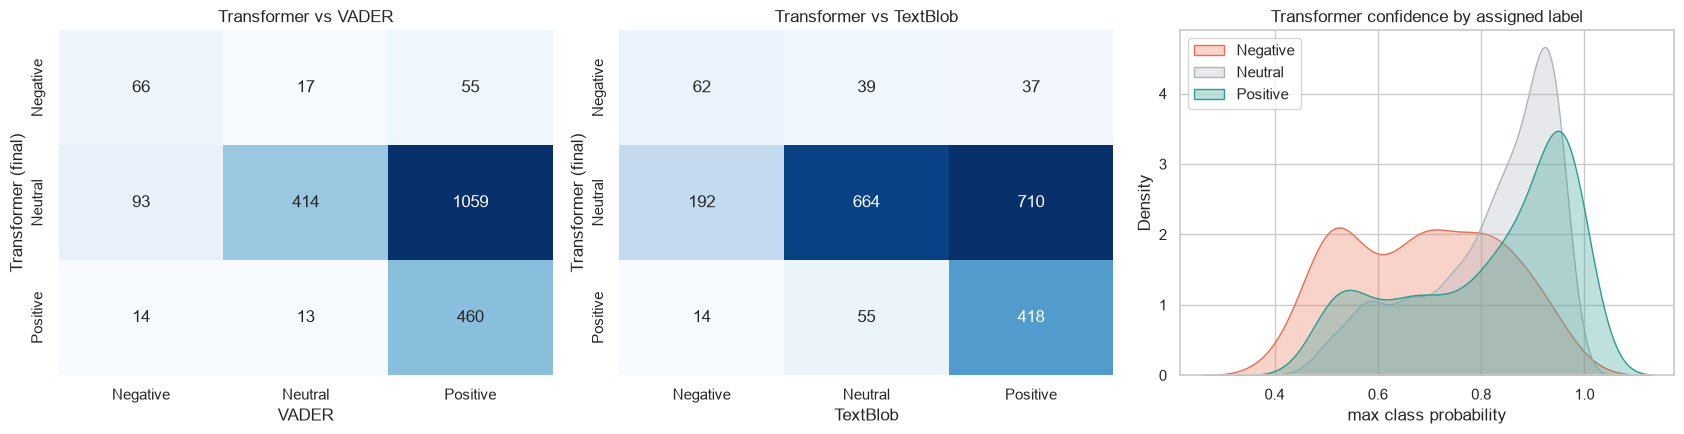

In [8]:
# Figure: confusion heatmaps against VADER and TextBlob, plus transformer confidence per label
fig, ax = plt.subplots(1, 3, figsize=(17, 4.5))
order = ["Negative", "Neutral", "Positive"]
for a, (name, col) in zip(ax[:2], [("VADER", "vader_sentiment"), ("TextBlob", "textblob_sentiment")]):
    cm = pd.crosstab(df["sentiment"], df[col]).reindex(index=order, columns=order, fill_value=0)
    sns.heatmap(cm, annot=True, fmt="d", cmap="Blues", ax=a, cbar=False)
    a.set(title=f"Transformer vs {name}", xlabel=name, ylabel="Transformer (final)")
# Confidence distribution of the transformer for each assigned label
for lab_ in order:
    sns.kdeplot(df.loc[df.sentiment == lab_, "confidence"], ax=ax[2], label=lab_, color=PALETTE[lab_], fill=True, alpha=.3)
ax[2].set(title="Transformer confidence by assigned label", xlabel="max class probability"); ax[2].legend()
save(fig, "01_label_validation.png")

**Observations – labeling**

* Final label distribution: **Neutral 1,566 (71.5%)**, **Positive 487 (22.2%)**, **Negative 138 (6.3%)**. That fits
  corporate e-mail, which is mostly scheduling, documents and FYIs.
* Mean transformer confidence is **0.81**. The highest-confidence examples make sense: promotion
  congratulations are Positive, "comed sucks!" is Negative, and logistics notes are Neutral.
* **Three methods compared:**

  | | Positive | Neutral | Negative | Agreement with transformer | Cohen's κ |
  |---|---|---|---|---|---|
  | Transformer (final) | 487 | 1,566 | 138 | – | – |
  | VADER | 1,574 | 444 | 173 | 42.9% | 0.17 |
  | TextBlob | 1,165 | 758 | 268 | 52.2% | 0.24 |

  VADER and TextBlob agree with each other more (65.3%, κ 0.36) than with the transformer. All three agree on 33.9% of messages.
* Both lexicon methods label far more messages Positive. They count polite words ("please", "thanks", "good",
  "great") as positive, so routine business e-mails come out positive. Most disagreements are therefore
  *Neutral (transformer) vs Positive (lexicon)*: 1,059 with VADER and 710 with TextBlob.
* Opposite-polarity disagreements (Positive vs Negative) are rare: **69 with VADER (3.1%)** and **51 with TextBlob (2.3%)**.
  In these the transformer is usually right. It labels *"Unfortunately, today is not going to work…"* and
  *"Please remove me from your email list"* as Negative where VADER says Positive. It also reads
  *"it wouldn't hurt to have another guy"* as Positive, where TextBlob sees "hurt" and says Negative.
* For this reason the transformer is kept as the source of truth, and VADER and TextBlob are used only as sanity checks.
  The transformer is the most conservative of the three, which suits a flight-risk use case where false
  "negative" flags have a cost.

## 2. Exploratory data analysis
### 2.1 Structure, types, missing values, duplicates

In [9]:
# Column types, missing values and duplicates in the raw data
print(raw.dtypes, "\n")
print("missing values:\n", raw.isna().sum(), "\n")
print("exact duplicate rows:", raw.duplicated().sum())
print("duplicate (employee, date, body):", df.duplicated(["employee", "date", "body"]).sum())
# Time span and number of senders
print("date range:", df.date.min().date(), "->", df.date.max().date(), f"({df.date.dt.to_period('M').nunique()} months)")
print("employees:", df.employee.nunique())
# Message length in characters and words (on the cleaned text)
df["char_len"] = df["clean_text"].str.len()
df["word_count"] = df["clean_text"].str.split().str.len()
df[["char_len", "word_count"]].describe().round(1)

Subject    str
body       str
date       str
from       str
dtype: object 

missing values:
 Subject    0
body       0
date       0
from       0
dtype: int64 

exact duplicate rows: 0
duplicate (employee, date, body): 0
date range: 2010-01-01 -> 2011-12-31 (24 months)
employees: 10


,char_len,word_count
count,2191.0,2191.0
mean,262.5,44.7
std,229.3,38.8
min,0.0,0.0
25%,91.0,16.0
50%,185.0,31.0
75%,358.0,61.0
max,1015.0,191.0


In [10]:
# Per-employee profile: message volume, sentiment mix and average length
emp_tbl = (df.groupby("employee")
             .agg(messages=("sentiment", "size"),
                  positive=("sentiment", lambda s: (s=="Positive").mean()),
                  neutral=("sentiment", lambda s: (s=="Neutral").mean()),
                  negative=("sentiment", lambda s: (s=="Negative").mean()),
                  avg_words=("word_count", "mean"))
             .sort_values("messages", ascending=False))
emp_tbl.style.format({"positive": "{:.1%}", "neutral": "{:.1%}", "negative": "{:.1%}", "avg_words": "{:.0f}"})

,messages,positive,neutral,negative,avg_words
employee,,,,,
lydia.delgado@enron.com,284,22.9%,71.1%,6.0%,45
john.arnold@enron.com,256,16.8%,75.0%,8.2%,47
sally.beck@enron.com,227,27.3%,67.0%,5.7%,44
patti.thompson@enron.com,225,20.4%,72.0%,7.6%,46
bobette.riner@ipgdirect.com,217,25.8%,65.4%,8.8%,44
don.baughman@enron.com,213,16.4%,78.9%,4.7%,43
johnny.palmer@enron.com,213,29.1%,65.7%,5.2%,44
eric.bass@enron.com,210,24.3%,71.9%,3.8%,48
kayne.coulter@enron.com,174,23.0%,70.7%,6.3%,45


### 2.2 Sentiment distribution

           count  share
sentiment              
Positive     487  0.222
Neutral     1566  0.715
Negative     138  0.063


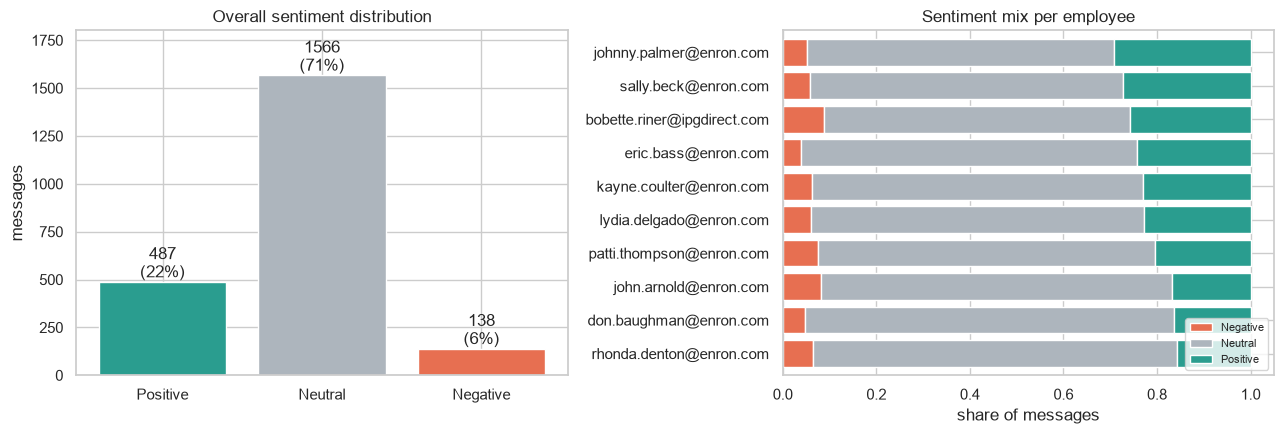

In [11]:
# Counts and shares of each sentiment label
dist = df["sentiment"].value_counts().reindex(["Positive", "Neutral", "Negative"])
print(pd.DataFrame({"count": dist, "share": (dist / len(df)).round(3)}))
fig, ax = plt.subplots(1, 2, figsize=(13, 4.5))
# Left: overall bar chart with counts and percentages
ax[0].bar(dist.index, dist.values, color=[PALETTE[k] for k in dist.index])
for i, v in enumerate(dist.values): ax[0].text(i, v, f"{v}\n({v/len(df):.0%})", ha="center", va="bottom")
ax[0].set(title="Overall sentiment distribution", ylabel="messages"); ax[0].margins(y=.15)
# Right: stacked share of each label per employee
share = pd.crosstab(df.employee, df.sentiment, normalize="index")[["Negative", "Neutral", "Positive"]].sort_values("Positive")
share.plot.barh(stacked=True, ax=ax[1], color=[PALETTE[c] for c in share.columns], width=.8)
ax[1].set(title="Sentiment mix per employee", xlabel="share of messages", ylabel=""); ax[1].legend(loc="lower right", fontsize=8)
save(fig, "02_sentiment_distribution.png")

### 2.3 Trends over time

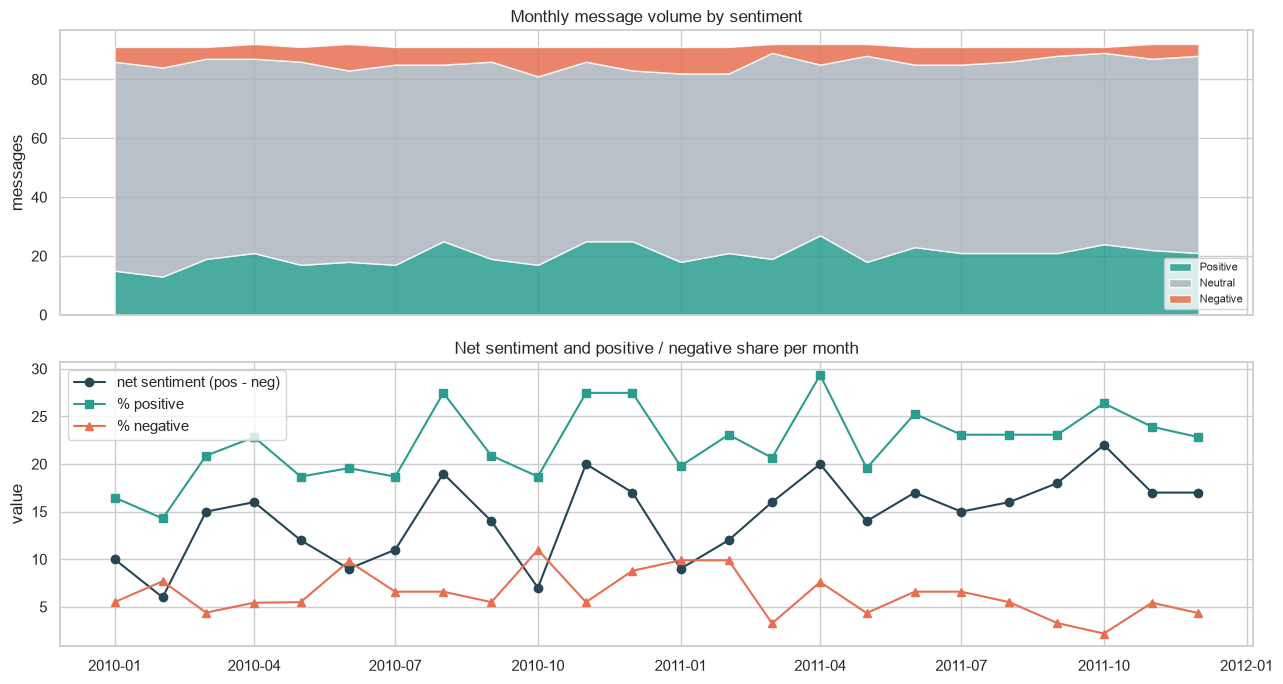

month,2010-01-01,2010-02-01,2010-03-01,2010-04-01,2010-05-01,2010-06-01,2010-07-01,2010-08-01,2010-09-01,2010-10-01,...,2011-03-01,2011-04-01,2011-05-01,2011-06-01,2011-07-01,2011-08-01,2011-09-01,2011-10-01,2011-11-01,2011-12-01
sentiment,,,,,,,,,,,,,,,,,,,,,
Positive,15,13,19,21,17,18,17,25,19,17,...,19,27,18,23,21,21,21,24,22,21
Neutral,71,71,68,66,69,65,68,60,67,64,...,70,58,70,62,64,65,67,65,65,67
Negative,5,7,4,5,5,9,6,6,5,10,...,3,7,4,6,6,5,3,2,5,4
total,91,91,91,92,91,92,91,91,91,91,...,92,92,92,91,91,91,91,91,92,92
net,10,6,15,16,12,9,11,19,14,7,...,16,20,14,17,15,16,18,22,17,17


In [12]:
# Count of each label per calendar month, and net sentiment (positive minus negative)
df["month"] = df["date"].dt.to_period("M")
m = pd.crosstab(df.month, df.sentiment)[["Positive", "Neutral", "Negative"]]
m.index = m.index.to_timestamp()
net = (m["Positive"] - m["Negative"])
fig, ax = plt.subplots(2, 1, figsize=(13, 7), sharex=True)
# Top: stacked monthly volume; bottom: net sentiment and positive / negative percentages
ax[0].stackplot(m.index, m.T.values, labels=m.columns, colors=[PALETTE[c] for c in m.columns], alpha=.85)
ax[0].set(title="Monthly message volume by sentiment", ylabel="messages"); ax[0].legend(loc="lower right", fontsize=8)
ax[1].plot(m.index, net, marker="o", color="#264653", label="net sentiment (pos - neg)")
ax[1].plot(m.index, (m["Positive"] / m.sum(axis=1)) * 100, marker="s", color=PALETTE["Positive"], label="% positive")
ax[1].plot(m.index, (m["Negative"] / m.sum(axis=1)) * 100, marker="^", color=PALETTE["Negative"], label="% negative")
ax[1].set(title="Net sentiment and positive / negative share per month", ylabel="value"); ax[1].legend()
save(fig, "03_sentiment_trend_monthly.png")
m.assign(total=m.sum(axis=1), net=net).T

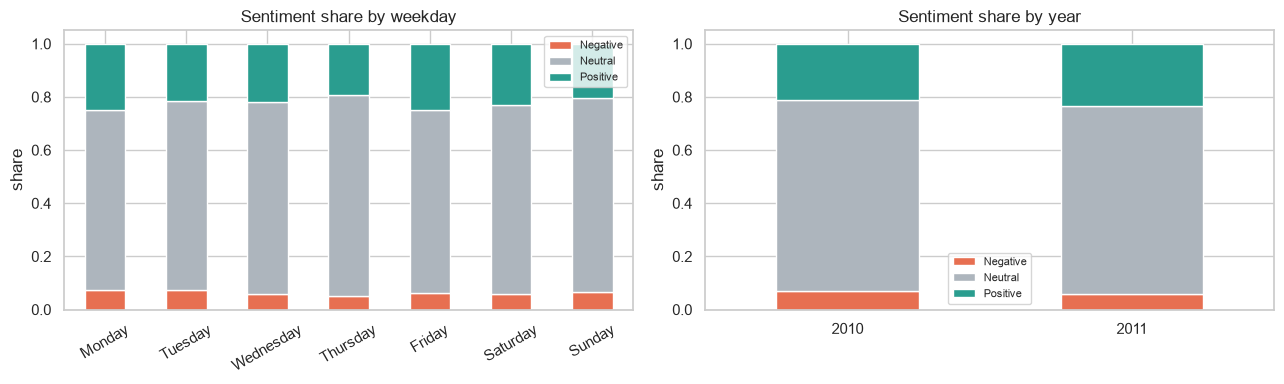

messages per weekday:
 date
Friday       339
Saturday     335
Sunday       334
Tuesday      303
Thursday     298
Wednesday    296
Monday       286
Name: count, dtype: int64


In [13]:
# Sentiment share by day of week (left) and by year (right)
fig, ax = plt.subplots(1, 2, figsize=(13, 4))
dow = pd.crosstab(df.date.dt.day_name(), df.sentiment, normalize="index")[["Negative","Neutral","Positive"]]
dow = dow.reindex(["Monday","Tuesday","Wednesday","Thursday","Friday","Saturday","Sunday"])
dow.plot.bar(stacked=True, ax=ax[0], color=[PALETTE[c] for c in dow.columns], rot=30)
ax[0].set(title="Sentiment share by weekday", ylabel="share", xlabel=""); ax[0].legend(fontsize=8)
yr = pd.crosstab(df.date.dt.year, df.sentiment, normalize="index")[["Negative","Neutral","Positive"]]
yr.plot.bar(stacked=True, ax=ax[1], color=[PALETTE[c] for c in yr.columns], rot=0)
ax[1].set(title="Sentiment share by year", ylabel="share", xlabel=""); ax[1].legend(fontsize=8)
save(fig, "04_weekday_year_patterns.png")
print("messages per weekday:\n", df.date.dt.day_name().value_counts())

### 2.4 Message length vs sentiment, and other patterns / anomalies

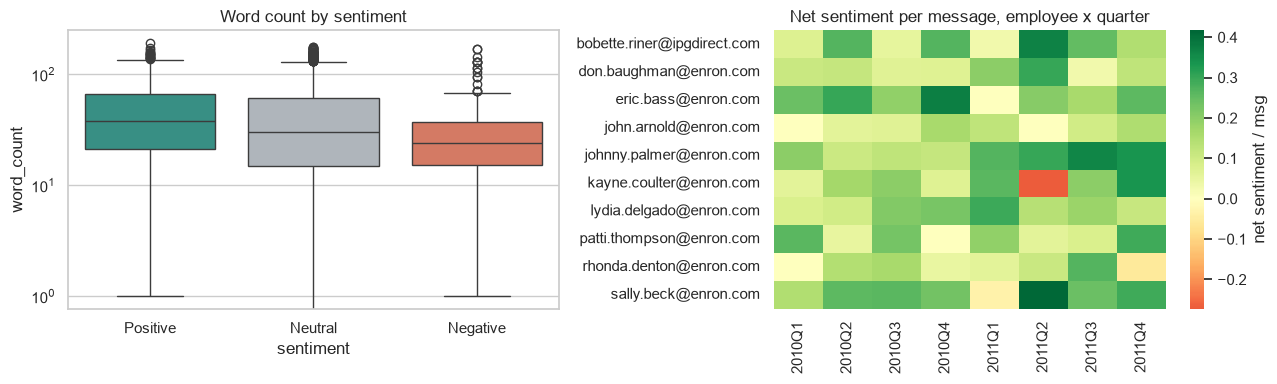

           char_len  word_count
sentiment                      
Negative      132.0        24.0
Neutral       184.5        30.0
Positive      211.0        38.0


In [14]:
# Left: word count per label (log scale, lengths are skewed)
fig, ax = plt.subplots(1, 2, figsize=(13, 4))
sns.boxplot(data=df, x="sentiment", y="word_count", order=["Positive","Neutral","Negative"], palette=PALETTE, ax=ax[0])
ax[0].set(title="Word count by sentiment", yscale="log")
# Right: net sentiment per message for each employee and quarter
heat = df.pivot_table(index="employee", columns=df.date.dt.to_period("Q").astype(str),
                      values="sentiment", aggfunc=lambda s: ((s=="Positive").sum()-(s=="Negative").sum())/len(s))
sns.heatmap(heat, cmap="RdYlGn", center=0, ax=ax[1], cbar_kws={"label": "net sentiment / msg"})
ax[1].set(title="Net sentiment per message, employee x quarter", xlabel="", ylabel="")
save(fig, "05_length_and_heatmap.png")
print(df.groupby("sentiment")[["char_len", "word_count"]].median())

In [15]:
# Anomalies: very short messages, subjects, repeated bodies
print("bodies under 20 characters:", (df.body.str.strip().str.len() < 20).sum())
print("'(No Subject)':", (df.Subject == "(No Subject)").sum())
print("replies (RE:):", df.Subject.str.match(r"(?i)^\s*re:").sum(), "| forwards (FW:):", df.Subject.str.match(r"(?i)^\s*fwd?:").sum())
print("\nmost repeated bodies:")
print(df.body.str.strip().str[:70].value_counts().head(5))
print("\nsentiment by reply/forward/new:")
# Classify each message by its subject prefix
kind = np.select([df.Subject.str.match(r"(?i)^\s*re:"), df.Subject.str.match(r"(?i)^\s*fwd?:")], ["reply", "forward"], "new")
pd.crosstab(kind, df.sentiment, normalize="index").round(3)

bodies under 20 characters: 100
'(No Subject)': 141
replies (RE:): 617 | forwards (FW:): 72

most repeated bodies:
body
                                                                          30
We have received the executed EEI Master Power Purchase and Sale Agree    26
fyi                                                                       11
Please find the interview packet for the above-referenced candidate.       8
The TradersNews hourly, daily and term indexes,  along with our indust     6
Name: count, dtype: int64

sentiment by reply/forward/new:


sentiment,Negative,Neutral,Positive
row_0,,,
forward,0.014,0.819,0.167
new,0.052,0.769,0.179
reply,0.096,0.571,0.334


**Observations – EDA**

* **Structure:** 2,191 messages, 4 text columns (`Subject`, `body`, `date`, `from`), **no missing values and no
  duplicate rows**. The data covers 10 employees and 24 months (Jan 2010 – Dec 2011).
* **Anomaly – evenly spread dates:** every month has 91–92 messages and weekends hold about 31% of the traffic
  (Sat 335, Sun 334, the busiest days next to Friday). The body text refers to 2000–2001 events while the dates
  are 2010–2011. The dates were most likely re-sampled when the dataset was built, so day-of-week and seasonal
  effects are not meaningful. Weekday and weekend sentiment are almost identical (6.3% negative for both).
* **Trend:** sentiment is stable over time. Net (pos − neg) per month ranges from **+6 (Feb 2010)** to
  **+22 (Oct 2011)**. 2011 is a little more positive than 2010 (23.3% vs 21.1% positive, 5.7% vs 6.9% negative).
  Oct 2010 has the most negative messages (10).
* **Employees:** johnny.palmer (29% positive) and sally.beck (27%) are the most positive. bobette.riner (8.8%)
  and john.arnold (8.2%) have the highest negative share. don.baughman and rhonda.denton are the most neutral (~78%).
* **Length:** negative messages are shorter (median 24 words) than neutral (30) and positive (38) ones. Complaints
  tend to be short and direct.
* **Message type:** replies (`RE:`) carry the most emotion: 9.6% negative and 33.4% positive, against 1.4% and
  16.7% for forwards. Back-and-forth conversation is where engagement, good or bad, shows up.
* **Other anomalies:** 30 empty bodies, 100 bodies under 20 characters, 141 "(No Subject)", and one automated
  notice ("We have received the executed EEI Master…") repeated 26 times. These are kept, because they are real
  messages an employee sent, and they are labeled Neutral as expected.

## 3. Monthly employee score

**Method**

* Each message scores **+1** (Positive), **−1** (Negative) or **0** (Neutral).
* Messages are grouped by `employee` and **calendar month** (`date.to_period("M")`, e.g. `2010-03`).
* The monthly score is the **sum of message scores inside that month only**. Because each month is its own
  group, the score automatically **resets to 0 at the start of every month** – nothing is carried over.
* The running (cumulative) score *within* a month is also computed per message so the reset can be verified.

In [16]:
# Message score: +1 Positive, -1 Negative, 0 Neutral
df["score"] = df["sentiment"].map(SCORE_MAP)
# Running total inside each employee-month (restarts every month)
df = df.sort_values(["employee", "date"]).reset_index(drop=True)
df["cum_score_in_month"] = df.groupby(["employee", "month"])["score"].cumsum()

# One row per employee and month with the monthly score and label counts
scores = monthly_scores(df)
scores.to_csv(OUT / "monthly_scores.csv", index=False)
print(scores.shape, "employee-month rows")
scores.head(10)

(240, 7) employee-month rows


,employee,month,score,n_messages,n_positive,n_negative,n_neutral
0,bobette.riner@ipgdirect.com,2010-01,0,2,0,0,2
1,don.baughman@enron.com,2010-01,1,9,2,1,6
2,eric.bass@enron.com,2010-01,3,10,3,0,7
3,john.arnold@enron.com,2010-01,-1,7,0,1,6
4,johnny.palmer@enron.com,2010-01,1,6,1,0,5
5,kayne.coulter@enron.com,2010-01,2,22,2,0,20
6,lydia.delgado@enron.com,2010-01,2,13,3,1,9
7,patti.thompson@enron.com,2010-01,2,10,3,1,6
8,rhonda.denton@enron.com,2010-01,0,3,0,0,3
9,sally.beck@enron.com,2010-01,0,9,1,1,7


all aggregation checks passed


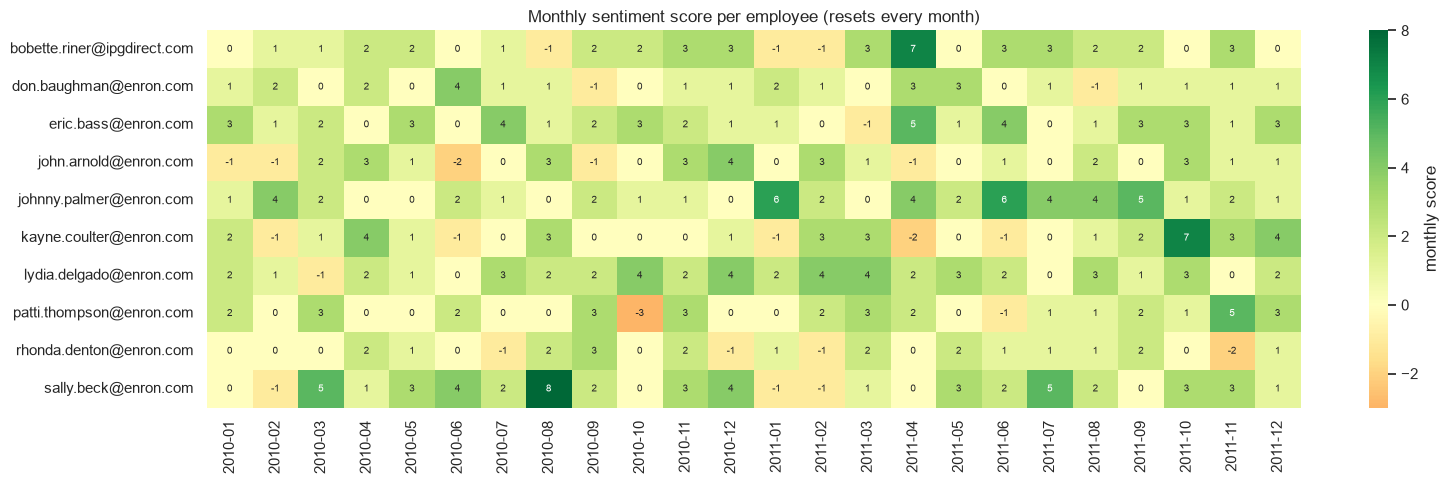

In [17]:
# --- validation of the aggregation ---
# 1) monthly score equals last cumulative value of the month
last_cum = df.groupby(["employee", "month"])["cum_score_in_month"].last().reset_index(name="last_cum")
chk = scores.merge(last_cum, on=["employee", "month"])
assert (chk.score == chk.last_cum).all()
# 2) score == positives - negatives, and counts add up
assert (scores.score == scores.n_positive - scores.n_negative).all()
assert scores.n_messages.sum() == len(df)
# 3) reset: the first message of each month has cumulative score equal to its own score
first = df.groupby(["employee", "month"]).head(1)
assert (first.cum_score_in_month == first.score).all()
print("all aggregation checks passed")

# Heatmap of every employee's monthly score
pivot = scores.pivot(index="employee", columns="month", values="score")
pivot.columns = pivot.columns.astype(str)
fig, ax = plt.subplots(figsize=(16, 5))
sns.heatmap(pivot, cmap="RdYlGn", center=0, annot=True, fmt=".0f", annot_kws={"size": 7}, ax=ax, cbar_kws={"label": "monthly score"})
ax.set(title="Monthly sentiment score per employee (resets every month)", xlabel="", ylabel="")
save(fig, "06_monthly_score_heatmap.png")

**Observations – scores**

* There are 240 employee-month rows: every employee is active in all 24 months. All aggregation checks pass:
  score = positives − negatives, message counts add up to 2,191, and the first message of each month
  starts a new running total (the reset is verified).
* Monthly scores range from **−3** (patti.thompson, Oct 2010) to **+8** (sally.beck, Aug 2010). The median is 1,
  and only 26 of 240 employee-months (11%) are negative.
* Because each message adds at most ±1, the score depends on volume. Busy employees can reach larger
  absolute scores. This is examined in Task 6.

## 4. Employee ranking

For **every month** (rankings are derived directly from the Task 3 table):

* **Top 3 positive** – sort by monthly score **descending**, ties broken **alphabetically** by employee.
* **Top 3 negative** – sort by monthly score **ascending** (most negative first), ties broken **alphabetically**.

Only employees who sent at least one message that month are ranked.

In [18]:
# Top 3 positive and top 3 negative employees for every month, saved as CSV
top_pos, top_neg = monthly_rankings(scores, k=3)
top_pos.to_csv(OUT / "top3_positive_by_month.csv", index=False)
top_neg.to_csv(OUT / "top3_negative_by_month.csv", index=False)

# Side-by-side table: one row per month, "name (score)" in each rank column
wide = lambda t: t.assign(cell=t.employee.str.replace("@enron.com", "").str.replace("@ipgdirect.com", "") + " (" + t.score.astype(str) + ")") \
                  .pivot(index="month", columns="rank", values="cell")
side = pd.concat({"Top 3 positive": wide(top_pos), "Top 3 negative": wide(top_neg)}, axis=1)
side

Top 3 positive                                               Top 3 negative                                         
rank                      1                   2                   3                    1                    2                   3
month                                                                                                                            
2010-01       eric.bass (3)   kayne.coulter (2)   lydia.delgado (2)     john.arnold (-1)    bobette.riner (0)   rhonda.denton (0)
2010-02   johnny.palmer (4)    don.baughman (2)   bobette.riner (1)     john.arnold (-1)   kayne.coulter (-1)     sally.beck (-1)
2010-03      sally.beck (5)  patti.thompson (3)       eric.bass (2)   lydia.delgado (-1)     don.baughman (0)   rhonda.denton (0)
2010-04   kayne.coulter (4)     john.arnold (3)   bobette.riner (2)        eric.bass (0)    johnny.palmer (0)  patti.thompson (0)
2010-05       eric.bass (3)      sally.beck (3)   bobette.riner (2)     don.baughman (0)    johnny.palmer (0)  patti.thompson (0)
2010-06    don.baughman (4)      sally.beck (4)   johnny.palmer (2)     john.arnold (-2)   kayne.coulter (-1)   bobette.riner (0)
2010-07       eric.bass (4)   lydia.delgado (3)      sally.beck (2)   rhonda.denton (-1)      john.arnold (0)   kayne.coulter (0)
2010-08      sally.beck (8)     john.arnold (3)   kayne.coulter (3)   bobette.riner (-1)    johnny.palmer (0)  patti.thompson (0)
2010-09  patti.thompson (3)   rhonda.denton (3)   bobette.riner (2)    don.baughman (-1)     john.arnold (-1)   kayne.coulter (0)
2010-10   lydia.delgado (4)       eric.bass (3)   bobette.riner (2)  patti.thompson (-3)     don.baughman (0)     john.arnold (0)
2010-11   bobette.riner (3)     john.arnold (3)  patti.thompson (3)    kayne.coulter (0)     don.baughman (1)   johnny.palmer (1)
2010-12     john.arnold (4)   lydia.delgado (4)      sally.beck (4)   rhonda.denton (-1)    johnny.palmer (0)  patti.thompson (0)
2011-01   johnny.palmer (6)    don.baughman (2)   lydia.delgado (2)   bobette.riner (-1)   kayne.coulter (-1)     sally.beck (-1)
2011-02   lydia.delgado (4)     john.arnold (3)   kayne.coulter (3)   bobette.riner (-1)   rhonda.denton (-1)     sally.beck (-1)
2011-03   lydia.delgado (4)   bobette.riner (3)   kayne.coulter (3)       eric.bass (-1)     don.baughman (0)   johnny.palmer (0)
2011-04   bobette.riner (7)       eric.bass (5)   johnny.palmer (4)   kayne.coulter (-2)     john.arnold (-1)   rhonda.denton (0)
2011-05    don.baughman (3)   lydia.delgado (3)      sally.beck (3)    bobette.riner (0)      john.arnold (0)   kayne.coulter (0)
2011-06   johnny.palmer (6)       eric.bass (4)   bobette.riner (3)   kayne.coulter (-1)  patti.thompson (-1)    don.baughman (0)
2011-07      sally.beck (5)   johnny.palmer (4)   bobette.riner (3)        eric.bass (0)      john.arnold (0)   kayne.coulter (0)
2011-08   johnny.palmer (4)   lydia.delgado (3)   bobette.riner (2)    don.baughman (-1)        eric.bass (1)   kayne.coulter (1)
2011-09   johnny.palmer (5)       eric.bass (3)   bobette.riner (2)      john.arnold (0)       sally.beck (0)    don.baughman (1)
2011-10   kayne.coulter (7)       eric.bass (3)     john.arnold (3)    bobette.riner (0)    rhonda.denton (0)    don.baughman (1)
2011-11  patti.thompson (5)   bobette.riner (3)   kayne.coulter (3)   rhonda.denton (-2)    lydia.delgado (0)    don.baughman (1)
2011-12   kayne.coulter (4)       eric.bass (3)  patti.thompson (3)    bobette.riner (0)     don.baughman (1)     john.arnold (1)

In [19]:
# Check, for every month, that rows are ordered by score and then alphabetically
for t, asc in [(top_pos, False), (top_neg, True)]:
    for _, g in t.groupby("month"):
        s = list(zip(g.score if asc else -g.score, g.employee))
        assert s == sorted(s)
print("ordering & alphabetical tie-break verified for all months")

# Show the rankings for the most recent month
latest = scores.month.max()
print("Latest month:", latest)
display(top_pos[top_pos.month == latest]); display(top_neg[top_neg.month == latest])

ordering & alphabetical tie-break verified for all months
Latest month: 2011-12


,month,rank,employee,score,n_messages
69,2011-12,1,kayne.coulter@enron.com,4,9
70,2011-12,2,eric.bass@enron.com,3,17
71,2011-12,3,patti.thompson@enron.com,3,12


,month,rank,employee,score,n_messages
69,2011-12,1,bobette.riner@ipgdirect.com,0,3
70,2011-12,2,don.baughman@enron.com,1,7
71,2011-12,3,john.arnold@enron.com,1,4


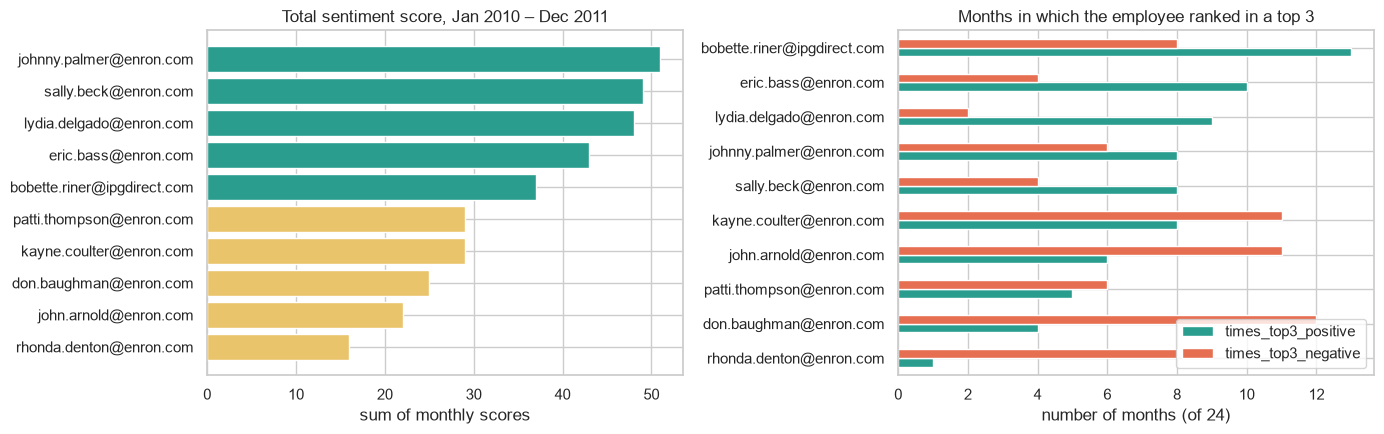

,employee,total_score,avg_monthly_score,months_active,times_top3_positive,times_top3_negative
0,johnny.palmer@enron.com,51,2.125000,24,8,6
1,sally.beck@enron.com,49,2.041667,24,8,4
2,lydia.delgado@enron.com,48,2.000000,24,9,2
3,eric.bass@enron.com,43,1.791667,24,10,4
4,bobette.riner@ipgdirect.com,37,1.541667,24,13,8
5,kayne.coulter@enron.com,29,1.208333,24,8,11
6,patti.thompson@enron.com,29,1.208333,24,5,6
7,don.baughman@enron.com,25,1.041667,24,4,12
8,john.arnold@enron.com,22,0.916667,24,6,11
9,rhonda.denton@enron.com,16,0.666667,24,1,8


In [20]:
# Overall view: total score across the whole period + how often each employee lands in a monthly top 3
overall = (scores.groupby("employee")
                 .agg(total_score=("score", "sum"), avg_monthly_score=("score", "mean"), months_active=("score", "size"))
                 .join(top_pos.employee.value_counts().rename("times_top3_positive"))
                 .join(top_neg.employee.value_counts().rename("times_top3_negative"))
                 .fillna(0).astype({"times_top3_positive": int, "times_top3_negative": int}))
overall = overall.reset_index().sort_values(["total_score", "employee"], ascending=[False, True]).reset_index(drop=True)
overall.to_csv(OUT / "overall_employee_ranking.csv", index=False)

# Left: total score per employee; right: number of months in each top-3 list
fig, ax = plt.subplots(1, 2, figsize=(14, 4.5))
o = overall.sort_values("total_score")
ax[0].barh(o.employee, o.total_score, color=["#2a9d8f" if v >= o.total_score.median() else "#e9c46a" for v in o.total_score])
ax[0].set(title="Total sentiment score, Jan 2010 – Dec 2011", xlabel="sum of monthly scores")
cnt = overall.set_index("employee")[["times_top3_positive", "times_top3_negative"]].sort_values("times_top3_positive")
cnt.plot.barh(ax=ax[1], color=[PALETTE["Positive"], PALETTE["Negative"]])
ax[1].set(title="Months in which the employee ranked in a top 3", xlabel="number of months (of 24)", ylabel="")
save(fig, "07_employee_rankings.png")
overall

**Observations – ranking**

* The ranking is computed from the Task 3 table for each of the 24 months. Ordering and alphabetical
  tie-breaks are checked by assertions.
* **Overall (sum of monthly scores):** johnny.palmer (51), sally.beck (49) and lydia.delgado (48) lead.
  rhonda.denton (16), john.arnold (22) and don.baughman (25) trail.
* **Dec 2011 (latest month):** positive – kayne.coulter (4), eric.bass (3), patti.thompson (3);
  negative – bobette.riner (0), don.baughman (1), john.arnold (1).
* Bottom-3 lists often contain scores of 0 or even positive values, because negative months are rare. A place in
  a "negative" list therefore means *least positive*, not necessarily unhappy.
* Volatility: bobette.riner is in the top 3 positive 13 times and the top 3 negative 8 times. don.baughman and
  kayne.coulter appear in the negative list most often (12 and 11 months).

## 5. Flight-risk identification

**Rule:** an employee is a flight risk if they sent **4 or more Negative messages within any rolling
30-day window**, regardless of calendar months and regardless of their score.

**Implementation:** each employee's Negative messages are sorted by date and scanned with a two-pointer
sliding window covering 30 calendar days inclusive (`date_j − date_i ≤ 29 days`). The maximum count in any
window is recorded together with the window dates. Every message counts (two on the same day = 2).

**Robustness:** the result is cross-checked against an independent brute-force implementation, and a
sensitivity check shows how the list changes with the threshold.

In [21]:
# Peak count of negatives in any rolling 30-day window, per employee
risk = flight_risk(df, threshold=4, window_days=30)
risk.to_csv(OUT / "flight_risk.csv", index=False)
flagged = risk.loc[risk.flight_risk, "employee"].tolist()
# The independent brute-force method must flag exactly the same employees
assert set(flagged) == flight_risk_bruteforce(df), "fast and brute-force results differ"
print("brute-force cross-check passed")
print(f"\nFLIGHT RISK employees ({len(flagged)}):", *flagged, sep="\n  ")
risk

brute-force cross-check passed

FLIGHT RISK employees (3):
  john.arnold@enron.com
  patti.thompson@enron.com
  rhonda.denton@enron.com


,employee,total_negative,max_negatives_in_30d,peak_window_start,peak_window_end,first_flagged_on,flight_risk
0,john.arnold@enron.com,21,4,2010-06-06,2010-06-21,2010-06-21,True
1,patti.thompson@enron.com,17,4,2010-10-04,2010-10-29,2010-10-29,True
2,rhonda.denton@enron.com,11,4,2010-12-24,2011-01-01,2011-01-01,True
3,bobette.riner@ipgdirect.com,19,3,2010-08-26,2010-09-16,NaT,False
4,lydia.delgado@enron.com,17,3,2011-04-16,2011-05-04,NaT,False
5,don.baughman@enron.com,10,2,2010-04-13,2010-05-03,NaT,False
6,eric.bass@enron.com,8,2,2011-05-17,2011-06-09,NaT,False
7,johnny.palmer@enron.com,11,2,2010-02-09,2010-03-10,NaT,False
8,kayne.coulter@enron.com,11,2,2010-12-31,2011-01-07,NaT,False
9,sally.beck@enron.com,13,2,2010-01-23,2010-02-15,NaT,False


In [22]:
# Sensitivity: how many employees would be flagged with other thresholds / window sizes
sens = pd.DataFrame({w: {t: flight_risk(df, t, w).flight_risk.sum() for t in [3, 4, 5, 6]} for w in [14, 30, 60]})
sens.index.name = "threshold (negatives)"; sens.columns.name = "window (days)"
sens

window (days),14,30,60
threshold (negatives),,,
3,2,5,7
4,1,3,5
5,0,0,4
6,0,0,0


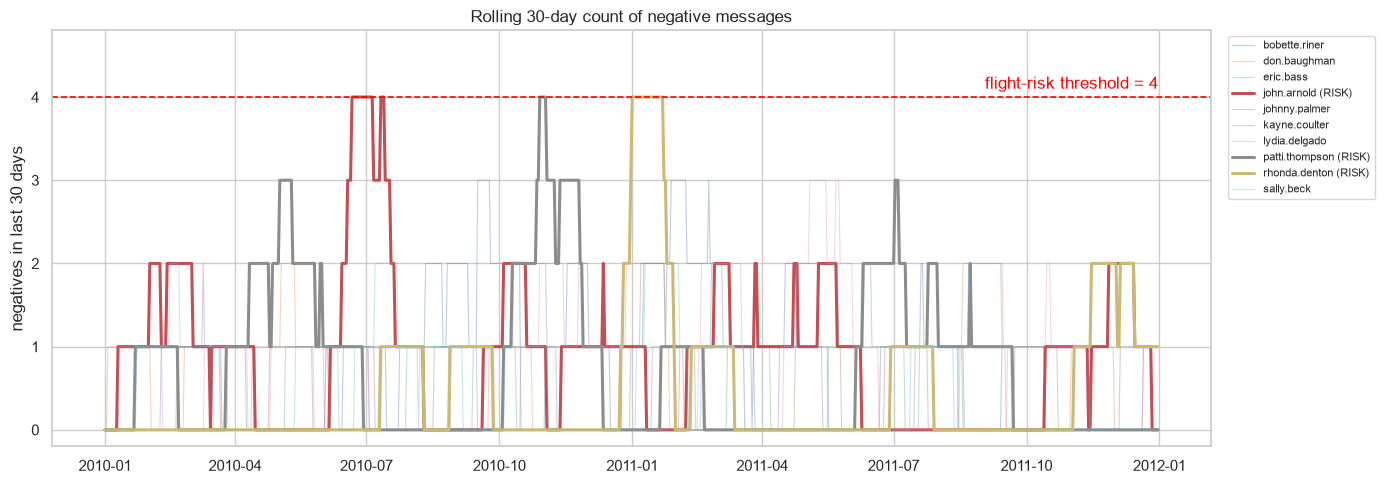

In [23]:
# Rolling 30-day negative count per employee over time
neg = df[df.sentiment == "Negative"].groupby(["employee", "date"]).size().rename("n").reset_index()
full_days = pd.date_range(df.date.min(), df.date.max(), freq="D")
fig, ax = plt.subplots(figsize=(14, 5))
for emp, g in neg.groupby("employee"):
    # Daily negatives filled to every calendar day, then summed over the last 30 days
    s =g.set_index("date")["n"].reindex(full_days, fill_value=0).rolling(30, min_periods=1).sum()
    ax.plot(s.index, s.values, lw=2.2 if emp in flagged else 0.8, alpha=1 if emp in flagged else .35,
            label=emp.split("@")[0] + (" (RISK)" if emp in flagged else ""))
ax.axhline(4, color="red", ls="--", lw=1.2); ax.text(full_days[-1], 4.1, "flight-risk threshold = 4", color="red", ha="right")
ax.set(title="Rolling 30-day count of negative messages", ylabel="negatives in last 30 days", ylim=(-0.2, 4.8))
ax.legend(fontsize=8, loc="upper left", bbox_to_anchor=(1.01, 1))
save(fig, "08_flight_risk_rolling.png")

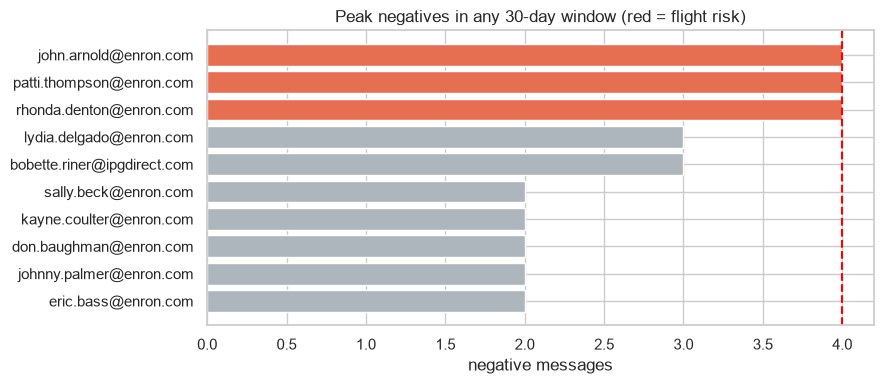

In [24]:
# Peak 30-day negative count per employee; flagged employees in red
fig, ax = plt.subplots(figsize=(9, 4))
r = risk.sort_values("max_negatives_in_30d")
ax.barh(r.employee, r.max_negatives_in_30d, color=[PALETTE["Negative"] if f else "#adb5bd" for f in r.flight_risk])
ax.axvline(4, color="red", ls="--"); ax.set(title="Peak negatives in any 30-day window (red = flight risk)", xlabel="negative messages")
save(fig, "09_flight_risk_peak.png")

**Observations – flight risk**

* **3 employees are flagged:** **john.arnold** (4 negatives between 2010-06-06 and 06-21), **patti.thompson**
  (4 between 2010-10-04 and 10-29) and **rhonda.denton** (4 between 2010-12-24 and 2011-01-01).
* rhonda.denton's window crosses a year boundary. A per-calendar-month count would have missed it,
  which shows why a rolling window is needed.
* The two-pointer implementation and an independent brute-force check return the same set.
* bobette.riner (19 negatives in total, peak 3) and lydia.delgado (17, peak 3) sit one message below the threshold.
  They are the next people to watch. With a threshold of 3, 5 employees would be flagged.
* The flags are driven by short bursts. John Arnold has the most negatives overall (21) and is flagged,
  but rhonda.denton has only 11 in total and is still flagged because 4 of them fall within 9 days.

## 6. Predictive modeling – linear regression

**Target:** monthly sentiment score of an employee (Task 3).
**Unit of observation:** employee-month (rows from Task 3).

**Features** – deliberately *not* derived from the sentiment labels (that would leak the target):

| feature | meaning |
|---|---|
| `n_messages` | messages sent in the month (frequency) |
| `avg_char_len`, `avg_word_count`, `total_words` | message length |
| `avg_subject_len` | subject length |
| `reply_ratio`, `fwd_ratio` | share of replies / forwards |
| `exclaim_per_msg`, `question_per_msg` | punctuation style |
| `weekend_ratio` | share sent on weekends |

**Evaluation:** 80/20 random train/test split (seed 42), 5-fold cross-validation, and a time-based split
(train 2010 → test 2011). Metrics: R², MAE, RMSE, compared with a mean-only baseline.

In [25]:
# Modeling tools from scikit-learn
from sklearn.linear_model import LinearRegression
from sklearn.preprocessing import StandardScaler
from sklearn.pipeline import make_pipeline
from sklearn.model_selection import train_test_split, cross_validate, KFold
from sklearn.metrics import r2_score, mean_absolute_error, mean_squared_error
from sklearn.dummy import DummyRegressor

# Employee-month features joined to the Task 3 score (the target)
feat = monthly_features(df).merge(scores[["employee", "month", "score"]], on=["employee", "month"])
FEATURES = ["n_messages", "avg_char_len", "avg_word_count", "total_words", "avg_subject_len",
            "reply_ratio", "fwd_ratio", "exclaim_per_msg", "question_per_msg", "weekend_ratio"]
X, y = feat[FEATURES], feat["score"]
print(feat.shape); feat[FEATURES + ["score"]].describe().T.round(2)

(240, 13)


,count,mean,std,min,25%,50%,75%,max
n_messages,240.0,9.13,5.73,1.0,4.75,9.00,12.00,27.0
avg_char_len,240.0,258.21,101.81,16.0,193.50,251.64,305.20,729.0
avg_word_count,240.0,44.24,17.88,3.0,33.00,43.16,51.84,130.0
total_words,240.0,408.42,282.33,3.0,166.00,390.50,583.00,1325.0
avg_subject_len,240.0,23.09,7.53,3.0,18.81,22.43,26.79,75.0
reply_ratio,240.0,0.28,0.22,0.0,0.14,0.27,0.38,1.0
fwd_ratio,240.0,0.04,0.12,0.0,0.00,0.00,0.05,1.0
exclaim_per_msg,240.0,0.24,0.34,0.0,0.00,0.17,0.33,3.0
question_per_msg,240.0,0.93,1.92,0.0,0.07,0.26,0.50,16.7
weekend_ratio,240.0,0.32,0.24,0.0,0.18,0.29,0.42,1.0


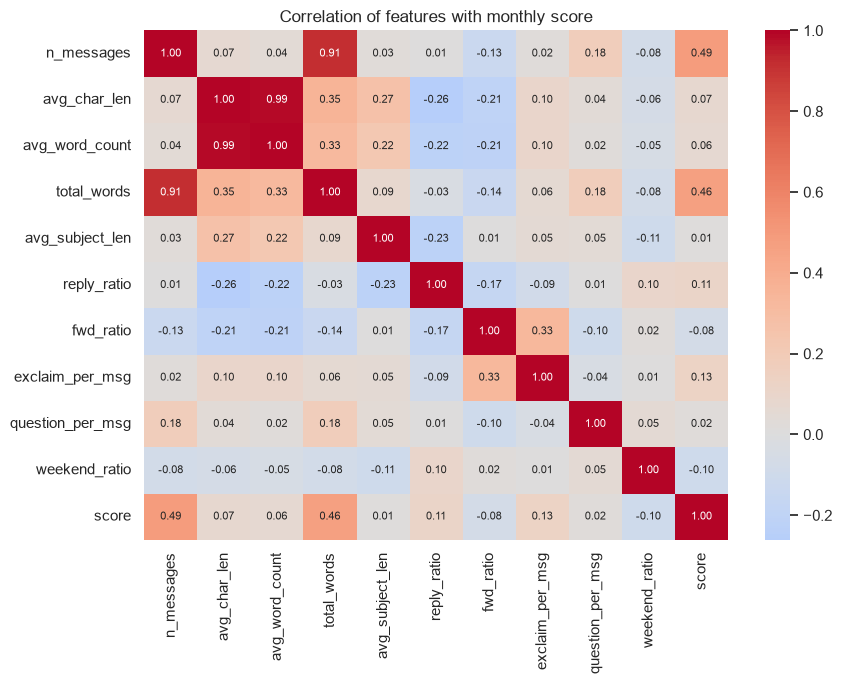

In [26]:
# Correlation between all features and the score, to spot drivers and collinearity
fig, ax = plt.subplots(figsize=(9, 7))
sns.heatmap(feat[FEATURES + ["score"]].corr(), annot=True, fmt=".2f", cmap="coolwarm", center=0, ax=ax, annot_kws={"size": 8})
ax.set_title("Correlation of features with monthly score")
save(fig, "10_feature_correlation.png")

In [27]:
def metrics(y_true, y_pred):
    """R2, MAE and RMSE for one set of predictions."""
    return {"R2": r2_score(y_true, y_pred), "MAE": mean_absolute_error(y_true, y_pred),
            "RMSE": mean_squared_error(y_true, y_pred) ** .5}

# 80/20 random split; scaled linear regression vs a predict-the-mean baseline
X_tr, X_te, y_tr, y_te = train_test_split(X, y, test_size=0.2, random_state=SEED)
model = make_pipeline(StandardScaler(), LinearRegression()).fit(X_tr, y_tr)
base = DummyRegressor().fit(X_tr, y_tr)

# time-based split: learn on 2010, predict 2011
is_2010 = feat.month.dt.year == 2010
model_t = make_pipeline(StandardScaler(), LinearRegression()).fit(X[is_2010], y[is_2010])

# 5-fold cross-validation on all rows
cv = cross_validate(make_pipeline(StandardScaler(), LinearRegression()), X, y,
                    cv=KFold(5, shuffle=True, random_state=SEED),
                    scoring=["r2", "neg_mean_absolute_error", "neg_root_mean_squared_error"])

# Collect all evaluations in one table
results = pd.DataFrame({
    "Linear reg - train": metrics(y_tr, model.predict(X_tr)),
    "Linear reg - test (random 20%)": metrics(y_te, model.predict(X_te)),
    "Baseline (mean) - test": metrics(y_te, base.predict(X_te)),
    "Linear reg - 5-fold CV (mean)": {"R2": cv["test_r2"].mean(), "MAE": -cv["test_neg_mean_absolute_error"].mean(),
                                      "RMSE": -cv["test_neg_root_mean_squared_error"].mean()},
    "Linear reg - time split (2011)": metrics(y[~is_2010], model_t.predict(X[~is_2010])),
}).T.round(3)
results.to_csv(OUT / "model_metrics.csv")
print("CV R2 per fold:", cv["test_r2"].round(3))
results

CV R2 per fold: [0.182 0.167 0.251 0.061 0.36 ]


,R2,MAE,RMSE
Linear reg - train,0.270,1.104,1.480
Linear reg - test (random 20%),0.182,1.123,1.517
Baseline (mean) - test,-0.153,1.440,1.801
Linear reg - 5-fold CV (mean),0.204,1.140,1.523
Linear reg - time split (2011),0.245,1.195,1.579


In [28]:
# OLS with standard errors and p-values, to see which features matter
coefs = ols_summary(pd.DataFrame(StandardScaler().fit_transform(X), columns=FEATURES), y)
coefs.to_csv(OUT / "model_coefficients.csv")
print("OLS on all rows, standardized features (coef = change in score per 1 SD of the feature)")
coefs.round(4)

OLS on all rows, standardized features (coef = change in score per 1 SD of the feature)


,coef,std_err,t,p_value
intercept,1.4542,0.0979,14.8603,0.0000
n_messages,0.8343,0.3411,2.4456,0.0152
avg_char_len,0.1214,0.7045,0.1723,0.8634
avg_word_count,-0.0308,0.6695,-0.0461,0.9633
total_words,0.0008,0.3631,0.0022,0.9982
avg_subject_len,0.0068,0.1077,0.0629,0.9499
reply_ratio,0.2396,0.1105,2.1693,0.0311
fwd_ratio,-0.0495,0.1135,-0.4359,0.6633
exclaim_per_msg,0.2331,0.1058,2.2034,0.0286
question_per_msg,-0.1084,0.1009,-1.0748,0.2836


In [29]:
# Parsimonious model: only the frequency feature, to show how much it alone explains
simple = LinearRegression().fit(X_tr[["n_messages"]], y_tr)
print("n_messages only  -> test R2 = %.3f, slope = %.3f per message" %
      (r2_score(y_te, simple.predict(X_te[["n_messages"]])), simple.coef_[0]))

n_messages only  -> test R2 = 0.190, slope = 0.140 per message


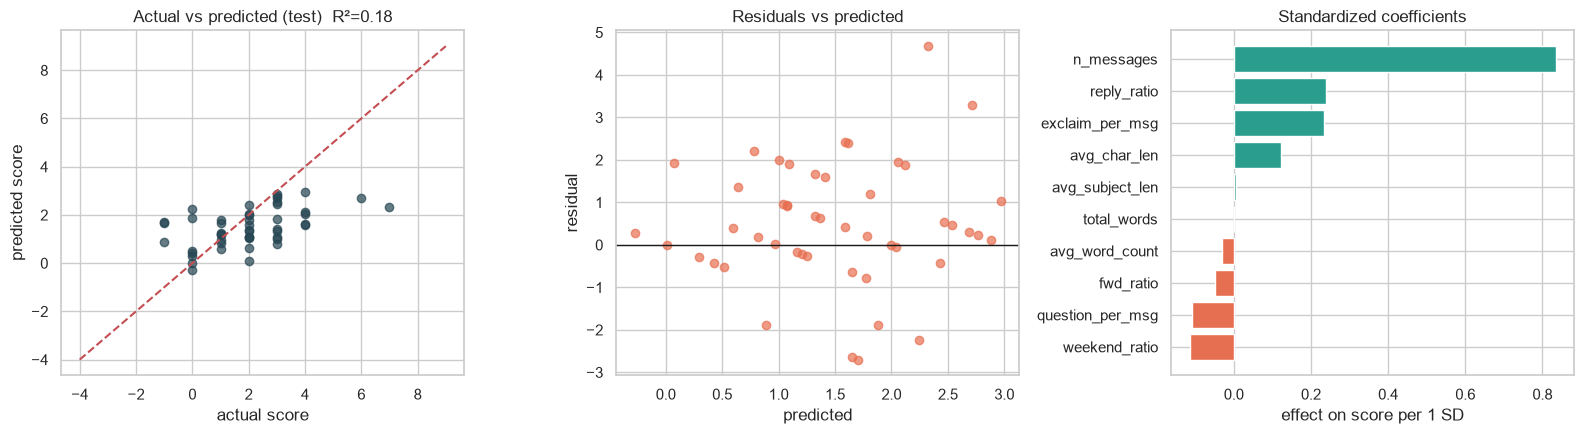

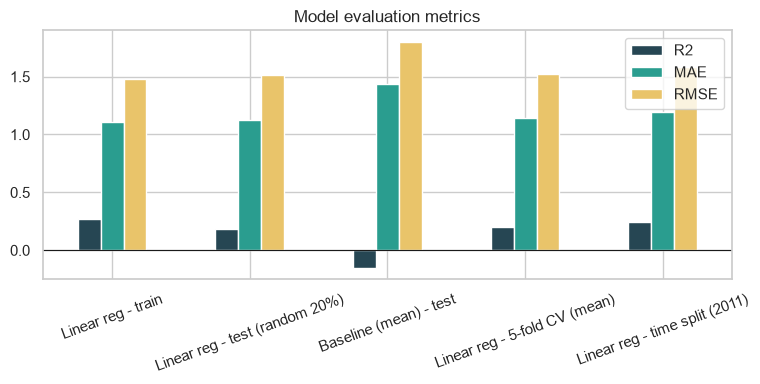

In [30]:
# Test-set predictions and residuals
pred = model.predict(X_te); resid = y_te - pred
fig, ax = plt.subplots(1, 3, figsize=(16, 4.5))
# Actual vs predicted (points on the red line are perfect predictions)
ax[0].scatter(y_te, pred, alpha=.7, color="#264653"); lim = [min(y.min(), pred.min()) - 1, max(y.max(), pred.max()) + 1]
ax[0].plot(lim, lim, "r--"); ax[0].set(title=f"Actual vs predicted (test)  R²={r2_score(y_te, pred):.2f}", xlabel="actual score", ylabel="predicted score")
# Residuals should scatter randomly around zero
ax[1].scatter(pred, resid, alpha=.7, color="#e76f51"); ax[1].axhline(0, color="k", lw=1)
ax[1].set(title="Residuals vs predicted", xlabel="predicted", ylabel="residual")
# Standardized coefficients: effect size of each feature
c = coefs.drop("intercept")["coef"].sort_values()
ax[2].barh(c.index, c.values, color=["#e76f51" if v < 0 else "#2a9d8f" for v in c.values])
ax[2].set(title="Standardized coefficients", xlabel="effect on score per 1 SD")
save(fig, "11_model_performance.png")

# Bar chart comparing metrics across the evaluation setups
fig, ax = plt.subplots(figsize=(8, 4))
results[["R2", "MAE", "RMSE"]].plot.bar(ax=ax, rot=20, color=["#264653", "#2a9d8f", "#e9c46a"])
ax.set(title="Model evaluation metrics"); ax.axhline(0, color="k", lw=.8)
save(fig, "12_model_metrics.png")

**Observations – model**

* The linear model beats the mean baseline clearly: on the test set, **MAE 1.12 vs 1.44** and **R² 0.18 vs −0.15**.
  Results are consistent across 5-fold CV (mean R² 0.20, fold range 0.06–0.36) and the time-based split
  (train 2010 → test 2011, R² 0.25). Train R² is 0.27, so overfitting is small.
* **Message frequency is the dominant and significant driver** (β = +0.83 per SD, p = 0.015). The single-feature
  model gives test R² 0.19 with a slope of **+0.14 score per extra message**. That is almost exactly the average
  net sentiment per message (22.2% pos − 6.3% neg = 0.159). In other words, the score partly measures
  activity: more messages give more chances to score +1.
* **Reply ratio (+0.24, p = 0.03)** and **exclamation marks per message (+0.23, p = 0.03)** are also significant
  and positive. Conversational, expressive writing goes with higher sentiment.
* Length features (`avg_char_len`, `avg_word_count`, `total_words`) are not significant and have very large
  standard errors because they are strongly collinear (r ≈ 0.99). The model could drop them without losing accuracy.
* An R² of about 0.2 means message metadata explains only a fifth of the variation in sentiment. The rest
  depends on what is said, so this model is useful for explaining patterns, not for predicting individual scores.
  The residuals widen for high predicted values (heteroscedasticity), which comes from scores being bounded counts.

## 7. Summary

In [31]:
# Final answers to the project questions
latest_pos = top_pos[top_pos.month == latest].employee.tolist()
latest_neg = top_neg[top_neg.month == latest].employee.tolist()
print("Overall top 3 positive (total score):", overall.head(3).employee.tolist())
print("Overall top 3 negative (total score):", overall.sort_values(["total_score","employee"]).head(3).employee.tolist())
print(f"Latest month {latest} top 3 positive:", latest_pos)
print(f"Latest month {latest} top 3 negative:", latest_neg)
print("Flight risks:", flagged)
print("Labeled data with sentiment column -> outputs/labeled_messages.csv")

Overall top 3 positive (total score): ['johnny.palmer@enron.com', 'sally.beck@enron.com', 'lydia.delgado@enron.com']
Overall top 3 negative (total score): ['rhonda.denton@enron.com', 'john.arnold@enron.com', 'don.baughman@enron.com']
Latest month 2011-12 top 3 positive: ['kayne.coulter@enron.com', 'eric.bass@enron.com', 'patti.thompson@enron.com']
Latest month 2011-12 top 3 negative: ['bobette.riner@ipgdirect.com', 'don.baughman@enron.com', 'john.arnold@enron.com']
Flight risks: ['john.arnold@enron.com', 'patti.thompson@enron.com', 'rhonda.denton@enron.com']
Labeled data with sentiment column -> outputs/labeled_messages.csv


**Summary of findings**

| | Result |
|---|---|
| Labels | 71.5% Neutral, 22.2% Positive, 6.3% Negative (RoBERTa transformer; VADER and TextBlob cross-checks) |
| Top 3 positive (overall) | johnny.palmer, sally.beck, lydia.delgado |
| Top 3 negative (overall) | rhonda.denton, john.arnold, don.baughman |
| Flight risks | **john.arnold, patti.thompson, rhonda.denton** |
| Watch list (3 negatives in 30 days) | bobette.riner, lydia.delgado |
| Model | Linear regression R² ≈ 0.2 (test / CV / time split); message frequency, reply ratio and exclamation use are significant |

**Recommendations:** reach out to the three flagged employees, starting with John Arnold (the most negatives
overall, and often in the bottom 3). Monitor the two employees on the watch list. Consider normalizing the score by
message volume (e.g. net sentiment per message) so that quiet employees are not ranked as "negative" just for
sending fewer e-mails.